### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [4]:
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

In [5]:
df = df.dropna(subset=['category', 'isBestSeller'])

In [6]:
#1. Crosstab analysis
category_bestseller_prop = pd.crosstab(df['category'], df['isBestSeller'], normalize='index')

In [7]:
category_bestseller_prop

isBestSeller,False,True
category,,
3D Printers,0.995968,0.004032
3D Printing & Scanning,0.999508,0.000492
Abrasive & Finishing Products,0.980000,0.020000
Action Cameras,0.999411,0.000589
Adapters,0.988189,0.011811
...,...,...
Wind Instruments,0.972000,0.028000
Window Treatments,0.979079,0.020921
Women,0.988015,0.011985


In [8]:
bs_col = [col for col in category_bestseller_prop.columns if col is True or str(col) == 'True'][0]

In [9]:
sorted_proportions = category_bestseller_prop.sort_values(by=bs_col, ascending=False)

print("Top 10 Categories by Best-Seller Prevalence")
print(sorted_proportions[bs_col].head(10))

Top 10 Categories by Best-Seller Prevalence
category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Wind Instruments                  0.028000
Mirrors                           0.028000
Name: True, dtype: float64


In [10]:
#2. Statistical tests
contingency_table = pd.crosstab(df['category'], df['isBestSeller'])
chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table)
n = contingency_table.sum().sum()
min_dim = min(contingency_table.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dim))

In [11]:
print("Statistical Test Results")
print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-Value: {p_value:.4f}")
print(f"Cramér's V: {cramers_v:.4f}")


Statistical Test Results
Chi-Square Statistic: 36540.2027
P-Value: 0.0000
Cramér's V: 0.1223


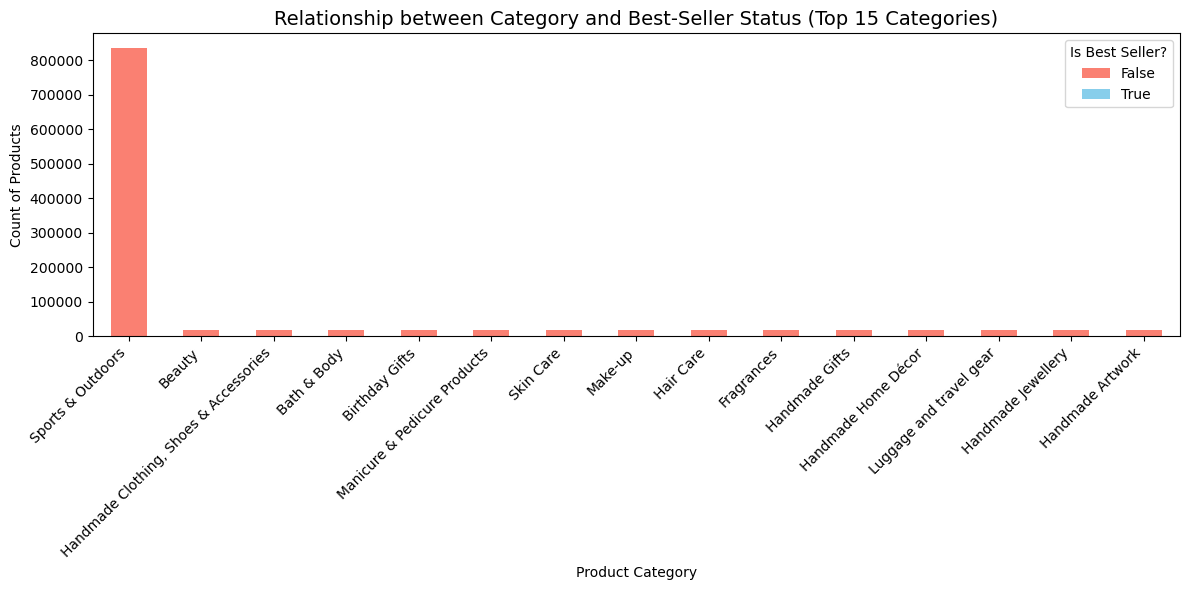

In [12]:
#3. Visualization 
top_15_categories = df['category'].value_counts().head(15).index
chart_data = contingency_table.loc[top_15_categories]
chart_data.plot(kind='bar', stacked=True, figsize=(12, 6), color=['salmon', 'skyblue'])

plt.title('Relationship between Category and Best-Seller Status (Top 15 Categories)', fontsize=14)
plt.xlabel('Product Category')
plt.ylabel('Count of Products')
plt.legend(title='Is Best Seller?', labels=['False', 'True'])
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [14]:
#0. Preliminary step
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [15]:
df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)].copy()

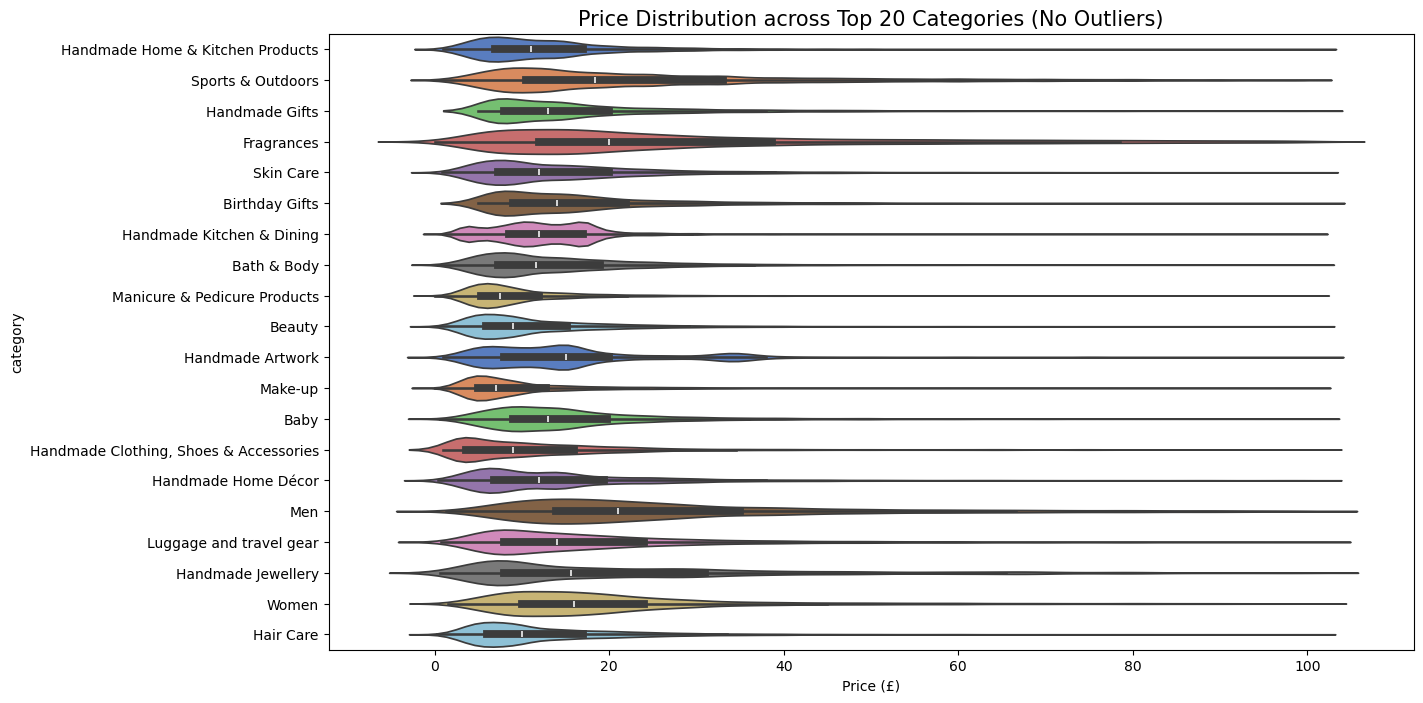

In [16]:
#1. Violin plots
top_20_cats = df_no_outliers['category'].value_counts().head(20).index
df_top20 = df_no_outliers[df_no_outliers['category'].isin(top_20_cats)]

plt.figure(figsize=(14, 8))
sns.violinplot(data=df_top20, x='price', y='category', hue='category', palette='muted', legend=False)
plt.title('Price Distribution across Top 20 Categories (No Outliers)', fontsize=15)
plt.xlabel('Price (£)')
plt.show()

In [19]:
median_prices = df_no_outliers.groupby('category')['price'].median().sort_values(ascending=False)
print(f"Category with the highest median price (all cathegories): {median_prices.index[0]} (£{median_prices.iloc[0]:.2f})")

Category with the highest median price (all cathegories): Desktop PCs (£74.00)


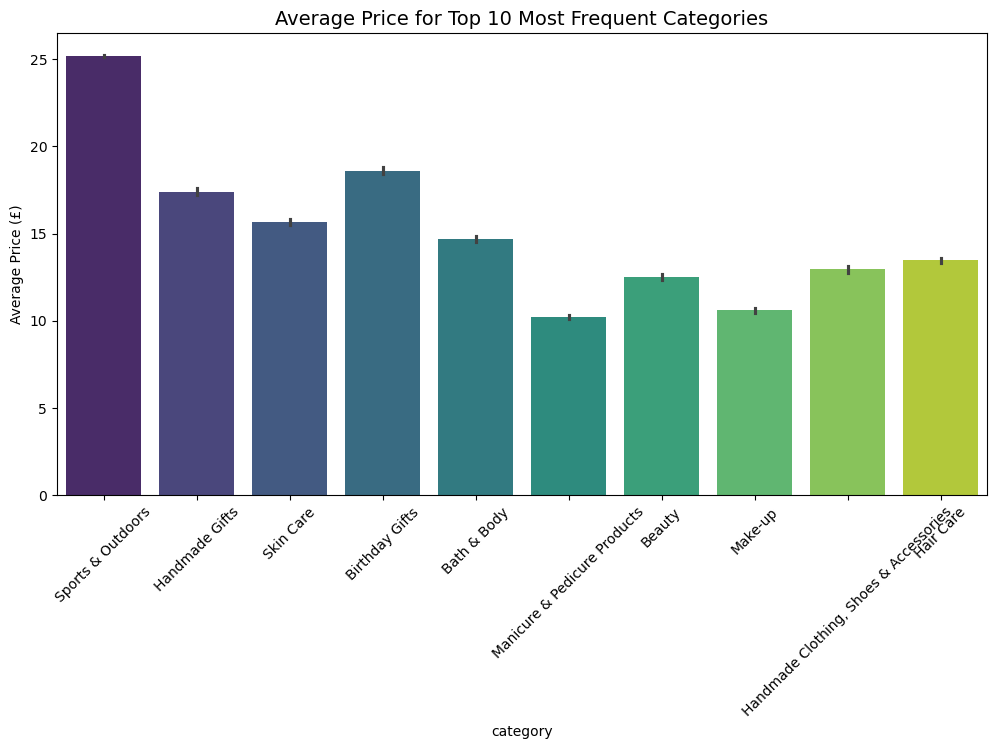

In [18]:
#2. Bar chart
top_10_cats = df_no_outliers['category'].value_counts().head(10).index
df_top10 = df_no_outliers[df_no_outliers['category'].isin(top_10_cats)]

plt.figure(figsize=(12, 6))
sns.barplot(data=df_top10, x='category', y='price', estimator='mean', palette='viridis', hue='category', legend=False)
plt.title('Average Price for Top 10 Most Frequent Categories', fontsize=14)
plt.xticks(rotation=45)
plt.ylabel('Average Price (£)')
plt.show()

In [ ]:
avg_prices = df_no_outliers.groupby('category')['price'].mean().sort_values(ascending=False)
print(f"Category with the highest average price (all cathegories): {avg_prices.index[0]} (£{avg_prices.iloc[0]:.2f})")

Category with the highest average price (all cathegories): Motherboards (£68.77)



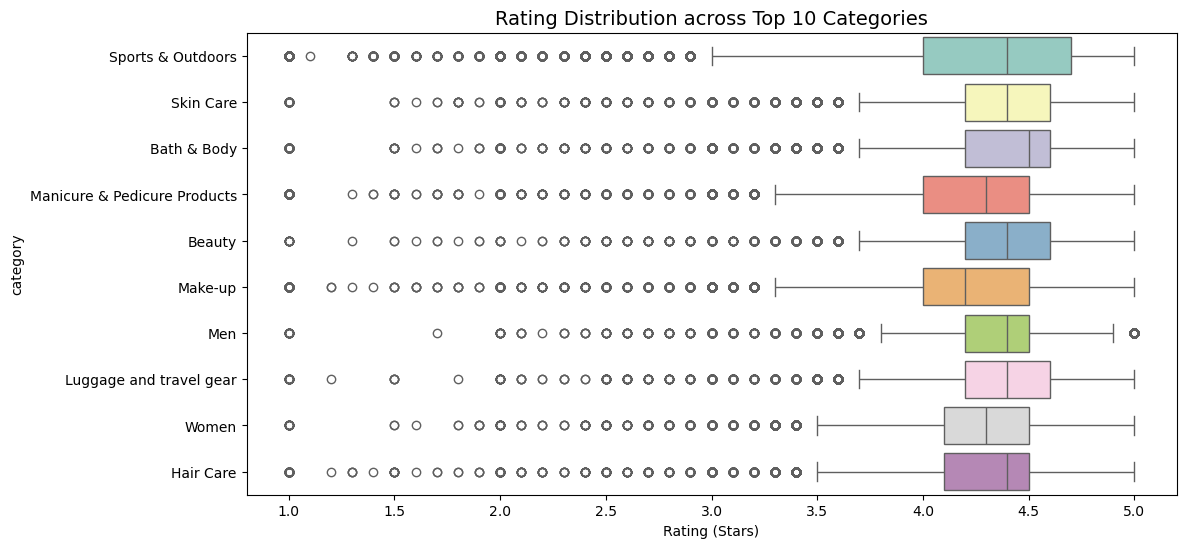

In [21]:
# 3. Boxplots
df_ratings_clean = df_no_outliers[df_no_outliers['stars'] > 0]
top_10_ratings_cats = df_ratings_clean['category'].value_counts().head(10).index
df_ratings_top10 = df_ratings_clean[df_ratings_clean['category'].isin(top_10_ratings_cats)]

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_ratings_top10, x='stars', y='category', hue='category', palette='Set3', legend=False)
plt.title('Rating Distribution across Top 10 Categories', fontsize=14)
plt.xlabel('Rating (Stars)')
plt.show()

In [22]:
median_ratings = df_ratings_clean.groupby('category')['stars'].median().sort_values(ascending=False)
print(f"Category with the highest median rating (all cathegories): {median_ratings.index[0]} ({median_ratings.iloc[0]} Stars)")

Category with the highest median rating (all cathegories): Made in Italy Handmade (5.0 Stars)


### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

---

**Bonus**: 

- Do the same analysis without taking out the outliers. What are your insights?

In [23]:
df_final = df_no_outliers[df_no_outliers['stars'] > 0].copy()

In [24]:
#1. Correlation coefficient
correlation = df_final['price'].corr(df_final['stars'])
print(f"Correlation between Price and Rating: {correlation:.4f}")

Correlation between Price and Rating: 0.0067


The calculated correlation coefficient between price and rating is 0.0067. This indicates a negligible or non-existent linear relationship between how much a product costs and how highly customers rate it.

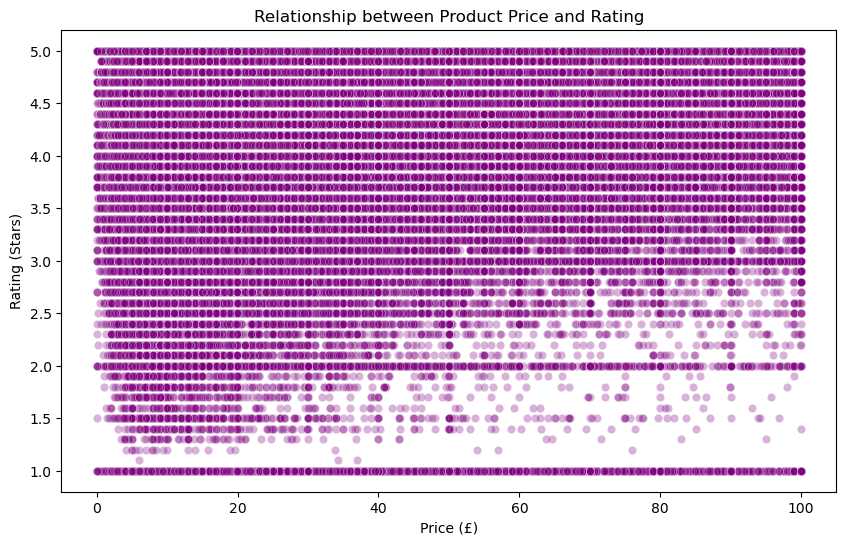

In [25]:
#2. Visualizations 
# Scatter Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_final, x='price', y='stars', alpha=0.3, color='purple')
plt.title('Relationship between Product Price and Rating')
plt.xlabel('Price (£)')
plt.ylabel('Rating (Stars)')
plt.show()


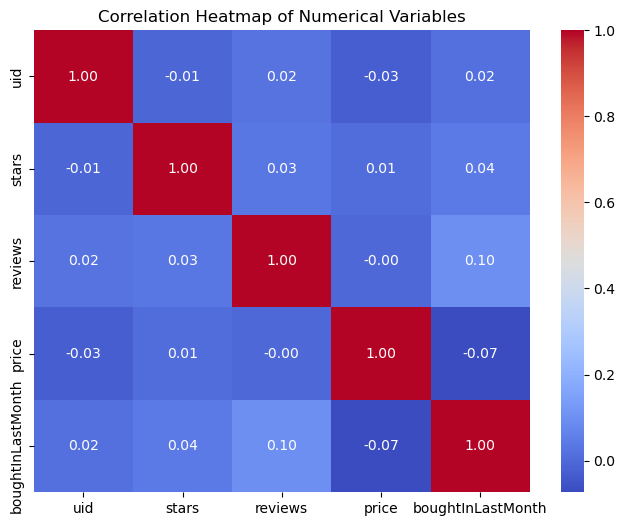

In [26]:
# Correlation Heatmap
# We select only numerical columns for the heatmap
numerical_df = df_final.select_dtypes(include=[np.number])
plt.figure(figsize=(8, 6))
sns.heatmap(numerical_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap of Numerical Variables')
plt.show()

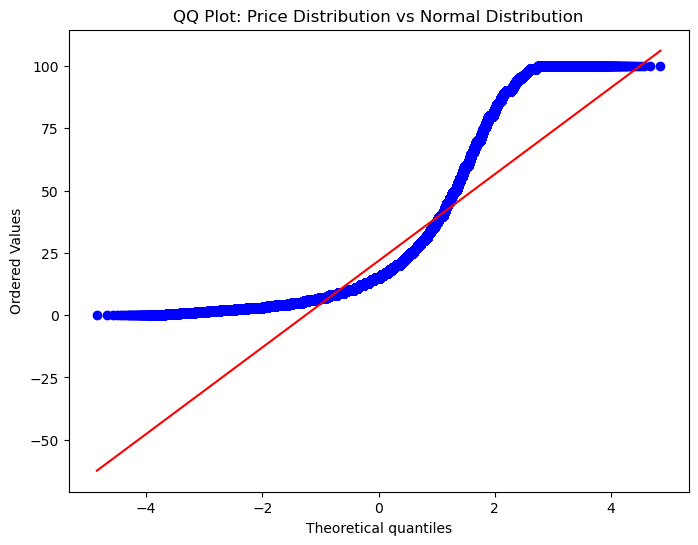

In [27]:
# QQ Plot for Price Normality
plt.figure(figsize=(8, 6))
stats.probplot(df_final['price'], dist="norm", plot=plt)
plt.title('QQ Plot: Price Distribution vs Normal Distribution')
plt.show()

The QQ Plot shows that product prices do not follow a normal distribution. The points deviate significantly from the red diagonal line, especially at the ends. This confirms that even after removing extreme outliers, the price distribution remains skewed and heavily concentrated in the lower range.

In [28]:
#BONUS
# 1. Correlation with Outliers
corr_with_outliers = df['price'].corr(df['stars'])

print("Analysis WITH Outliers")
print(f"Correlation (With Outliers): {corr_with_outliers:.4f}")
print(f"Correlation (Without Outliers - Previous): {correlation:.4f}")


Analysis WITH Outliers
Correlation (With Outliers): -0.1249
Correlation (Without Outliers - Previous): 0.0067


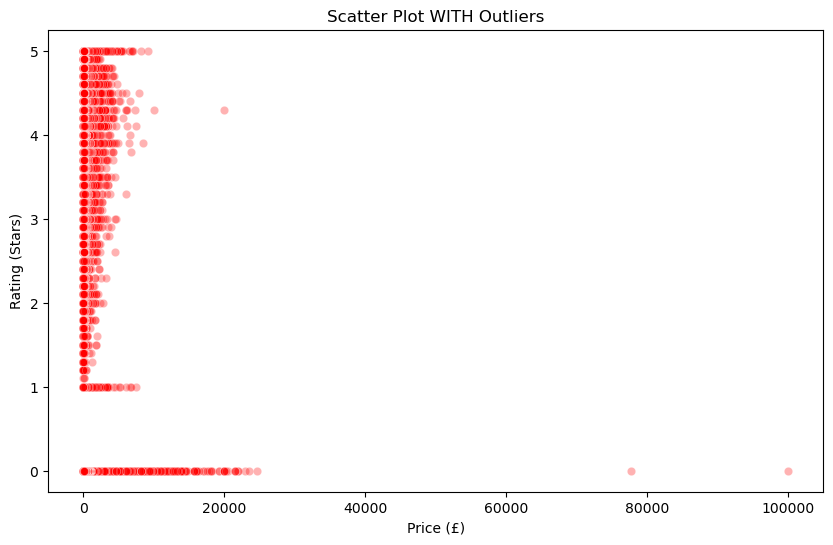

In [29]:
# 2. Scatter Plot with Outliers
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='price', y='stars', alpha=0.3, color='red')
plt.title('Scatter Plot WITH Outliers')
plt.xlabel('Price (£)')
plt.ylabel('Rating (Stars)')
plt.show()

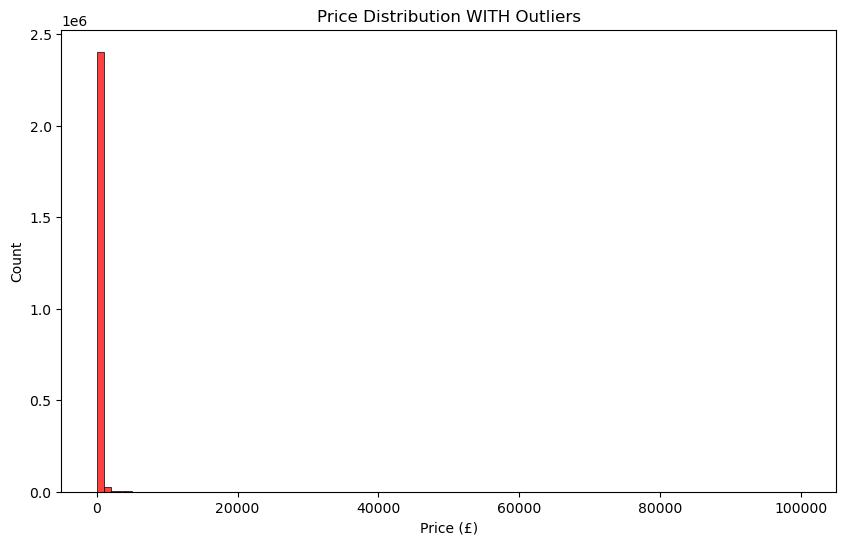

In [30]:
# 3. Distribution Comparison (Histogram)
plt.figure(figsize=(10, 6))
sns.histplot(df['price'], bins=100, color='red', kde=False)
plt.title('Price Distribution WITH Outliers')
plt.xlabel('Price (£)')
plt.show()